1.导入所需要的库

In [1]:
from sklearn.model_selection import cross_val_score,train_test_split,GridSearchCV
from sklearn import tree
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder,OneHotEncoder,KBinsDiscretizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold,SelectKBest,chi2
from sklearn.metrics import confusion_matrix,roc_auc_score,roc_curve
from sklearn.linear_model import LogisticRegression as lr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import graphviz
import warnings
warnings.filterwarnings('ignore')

2.导入数据

In [2]:
data=pd.read_csv(r"C:\Users\Y7000\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv",encoding='utf-8')

3.观察数据形态

In [3]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


4.删除不需要的feature

In [4]:
data=data.drop(["customerID"],axis=1)

5.切分数据，防止污染

In [5]:
Xtrain,Xtest,Ytrain,Ytest=train_test_split(data.iloc[:,0:-1],data["Churn"],test_size=0.3,random_state=1)

6.观察各feature空值，缺失值，异常值，对照train，test两组取数是否异常，并用train组填充test组

In [6]:
Xtrain.info()
Xtest.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4930 entries, 5925 to 5157
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            4930 non-null   object 
 1   SeniorCitizen     4930 non-null   int64  
 2   Partner           4930 non-null   object 
 3   Dependents        4930 non-null   object 
 4   tenure            4930 non-null   int64  
 5   PhoneService      4930 non-null   object 
 6   MultipleLines     4930 non-null   object 
 7   InternetService   4930 non-null   object 
 8   OnlineSecurity    4930 non-null   object 
 9   OnlineBackup      4930 non-null   object 
 10  DeviceProtection  4930 non-null   object 
 11  TechSupport       4930 non-null   object 
 12  StreamingTV       4930 non-null   object 
 13  StreamingMovies   4930 non-null   object 
 14  Contract          4930 non-null   object 
 15  PaperlessBilling  4930 non-null   object 
 16  PaymentMethod     4930 non-null   object 
 1

观察到TotalCharges格式为object，这里进行转换,并填充空值为0（因为根据业务逻辑，此时大概率tenure为0，自然Charges为0）

In [7]:
Xtrain["TotalCharges"]=pd.to_numeric(Xtrain["TotalCharges"],errors='coerce')
Xtest["TotalCharges"]=pd.to_numeric(Xtest["TotalCharges"],errors='coerce')
Xtrain.fillna(0,inplace=True)
Xtest.fillna(0,inplace=True)

In [8]:
Xtrain.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,4930.000000,4930.000000,4930.000000,4930.00000
mean,0.162069,32.214807,64.791176,2274.60786
std,0.368551,24.555738,30.127626,2270.61300
min,0.000000,0.000000,18.250000,0.00000
25%,0.000000,8.000000,35.400000,385.78750
50%,0.000000,29.000000,70.400000,1388.97500
75%,0.000000,55.000000,89.850000,3772.61250
max,1.000000,72.000000,118.650000,8684.80000


In [9]:
Xtest.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,2113.000000,2113.000000,2113.000000,2113.000000
mean,0.162328,32.735920,64.692901,2291.695196
std,0.368839,24.570155,30.009194,2258.351069
min,0.000000,0.000000,18.700000,0.000000
25%,0.000000,9.000000,36.150000,416.450000
50%,0.000000,29.000000,70.250000,1406.900000
75%,0.000000,56.000000,89.900000,3815.400000
max,1.000000,72.000000,118.750000,8672.450000


7.接下来在对特征矩阵中的连续值进行画图观察图像形态

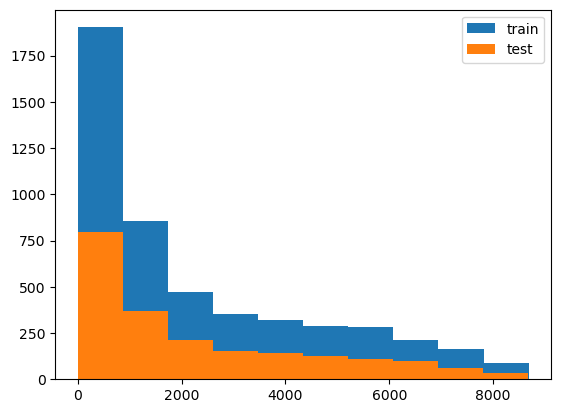

In [10]:
plt.hist(Xtrain["TotalCharges"],label='train')
plt.hist(Xtest["TotalCharges"],label='test')
plt.legend()

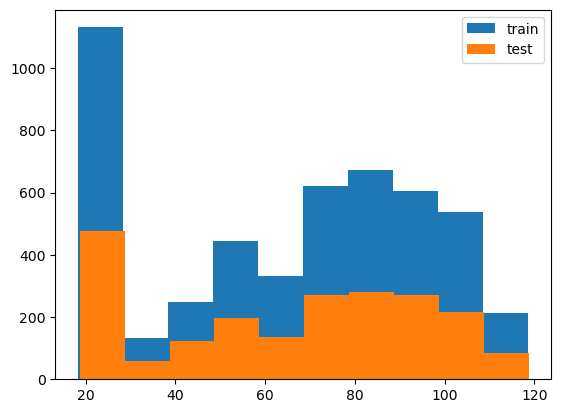

In [11]:
plt.hist(Xtrain["MonthlyCharges"],label="train")
plt.hist(Xtest["MonthlyCharges"],label='test')
plt.legend()

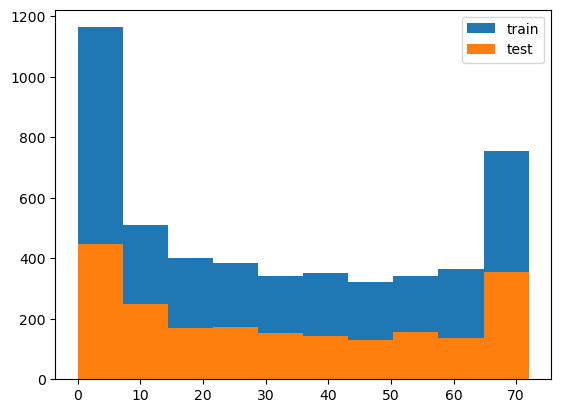

In [12]:
plt.hist(Xtrain["tenure"],label="train")
plt.hist(Xtest["tenure"],label='test')
plt.legend()

得出结论：对于TotalCharges偏态严重，MonthlyCharges非线性分布呈现双峰，tenure非线性凹状态所以这里考虑对两个连续变量分箱处理,即TotalCharges，tenure等频，MonthlyCharges聚类。另外保存分箱结果防止覆盖原始数据

In [13]:
kbd_total=KBinsDiscretizer(n_bins=4,strategy='quantile',encode='ordinal')
train_new_total=kbd_total.fit_transform(Xtrain["TotalCharges"].values.reshape(-1,1))
test_new_total=kbd_total.transform(Xtest["TotalCharges"].values.reshape(-1,1))

In [14]:
kbd_tenure=KBinsDiscretizer(n_bins=4,strategy='quantile',encode='ordinal')
train_new_tenure=kbd_tenure.fit_transform(Xtrain["tenure"].values.reshape(-1,1))
test_new_tenure=kbd_tenure.transform(Xtest["tenure"].values.reshape(-1,1))

In [15]:
kbd_monthly=KBinsDiscretizer(n_bins=4,strategy='kmeans',encode='ordinal')
train_new_monthly=kbd_monthly.fit_transform(Xtrain["MonthlyCharges"].values.reshape(-1,1))
test_new_monthly=kbd_monthly.transform(Xtest["MonthlyCharges"].values.reshape(-1,1))

8.接下来对特征矩阵和label进行编码，根据业务逻辑，这里选择独热编码

In [16]:
le=LabelEncoder()
Ytrain=le.fit_transform(Ytrain)
Ytest=le.transform(Ytest)

In [17]:
Xtrain_clear=Xtrain.drop(['tenure','TotalCharges','MonthlyCharges'],axis=1)
Xtrain_base=pd.DataFrame({'tenure':train_new_tenure.flatten()
                          ,'TotalCharges':train_new_total.flatten()
                          ,'MonthlyCharges':train_new_monthly.flatten()
                         },index=Xtrain.index)
Xtrain_clear=pd.concat([Xtrain_clear,Xtrain_base],axis=1)

In [18]:
Xtest_clear=Xtest.drop(['tenure','TotalCharges','MonthlyCharges'],axis=1)
Xtest_base=pd.DataFrame({'tenure':test_new_tenure.flatten()
                          ,'TotalCharges':test_new_total.flatten()
                          ,'MonthlyCharges':test_new_monthly.flatten()
                         },index=Xtest.index)
Xtest_clear=pd.concat([Xtest_clear,Xtest_base],axis=1)

In [19]:
columns=Xtrain_clear.columns
ohe=OneHotEncoder(drop="first",sparse_output=False)
array_Xtrain=ohe.fit_transform(Xtrain_clear)
array_Xtest=ohe.transform(Xtest_clear)
new_columns=ohe.get_feature_names_out(columns)
Xtrain_clear=pd.DataFrame(array_Xtrain,columns=new_columns,index=Xtrain_clear.index)
Xtest_clear=pd.DataFrame(array_Xtest,columns=new_columns,index=Xtest_clear.index)

In [20]:
Xtrain_clear.head()

,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,...,PaymentMethod_Mailed check,tenure_1.0,tenure_2.0,tenure_3.0,TotalCharges_1.0,TotalCharges_2.0,TotalCharges_3.0,MonthlyCharges_1.0,MonthlyCharges_2.0,MonthlyCharges_3.0
5925,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4395,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1579,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1040,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1074,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


9.那么现在可以对特征矩阵进行feature selection，这里选择卡方筛选和方差筛选

In [21]:
V=VarianceThreshold(0.01)
Xtrain_clear_1=V.fit_transform(Xtrain_clear)
Xtest_clear_1=V.transform(Xtest_clear)

In [22]:
K=SelectKBest(chi2,k=15)
Xtrain_clear_=K.fit_transform(Xtrain_clear_1,Ytrain)
Xtest_clear_=K.transform(Xtest_clear_1)

In [23]:
features=new_columns[K.get_support()]
Xtrain_final=pd.DataFrame(Xtrain_clear_,columns=features)
Xtest_final=pd.DataFrame(Xtest_clear_,columns=features)

In [24]:
Xtrain_final.head()

,SeniorCitizen_1,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,DeviceProtection_No internet service,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingMovies_No internet service,Contract_One year,Contract_Two year,PaymentMethod_Electronic check,tenure_3.0
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0


10.现在开始对随机森林开始建模，用交叉验证对比方差筛选和卡方筛选,画出特征图并解读业务,得出auc得分,画出混淆矩阵，并让准确率，召回率可视化

In [25]:
rfc=RandomForestClassifier(n_estimators=100,class_weight="balanced",random_state=3)
rfc=rfc.fit(Xtrain_final,Ytrain)
score1=rfc.score(Xtest_final,Ytest)

In [26]:
score1

0.7434926644581165

In [27]:
cross_val_score(rfc,Xtrain_clear_1,Ytrain,cv=5,scoring='roc_auc').mean()

np.float64(0.7929751752714337)

In [28]:
cross_val_score(rfc,Xtrain_final,Ytrain,cv=5,scoring='roc_auc').mean()

np.float64(0.8055823768866702)

In [29]:
importances=rfc.feature_importances_
df_importances=pd.DataFrame({"feature":Xtrain_final.columns,'importances':importances}).sort_values(by='importances',ascending=False).reset_index(drop=True)
df_importances

,feature,importances
0,Contract_Two year,0.208591
1,InternetService_Fiber optic,0.131378
2,Contract_One year,0.122573
3,tenure_3.0,0.117780
4,PaymentMethod_Electronic check,0.114104
5,OnlineSecurity_Yes,0.077631
6,TechSupport_Yes,0.070497
7,SeniorCitizen_1,0.031136
8,OnlineSecurity_No internet service,0.023683
9,TechSupport_No internet service,0.021856


<Axes: >

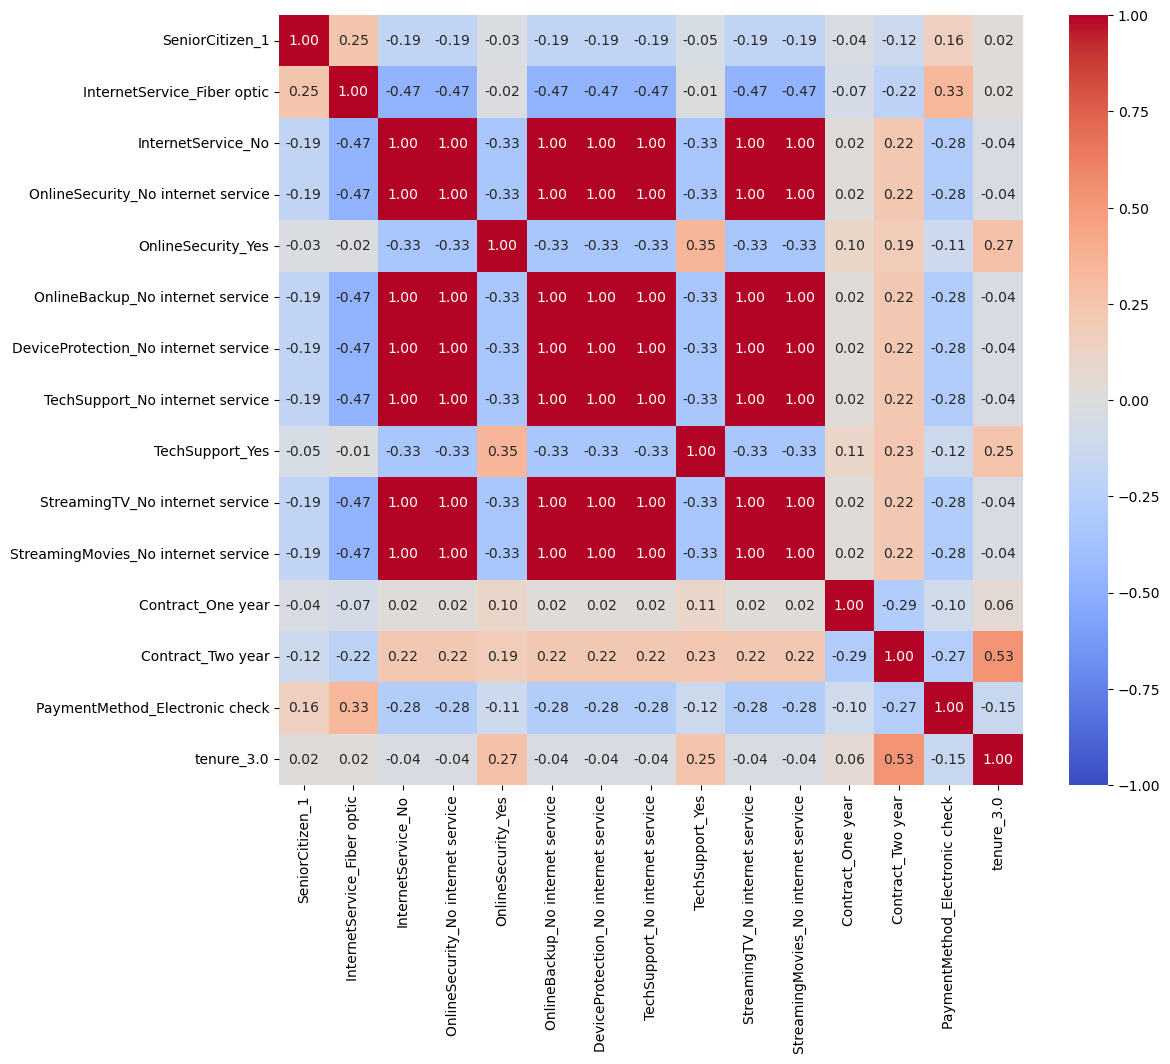

In [30]:
plt.figure(figsize=(12,10))
sns.heatmap(Xtrain_final.corr(),annot=True,vmin=-1,vmax=1,cmap='coolwarm',fmt='.2f')

观察图像可知有一部分feature存在多重共线性，这在一会的逻辑回归中需要去除

In [31]:
y_pred=rfc.predict(Xtest_final)
y_pred_proba=rfc.predict_proba(Xtest_final)[:,1]
auc=roc_auc_score(Ytest,y_pred_proba)
auc

0.8306603097218239

In [32]:
cm=confusion_matrix(Ytest,y_pred)
cm

array([[1150,  435],
       [ 107,  421]])

<Axes: >

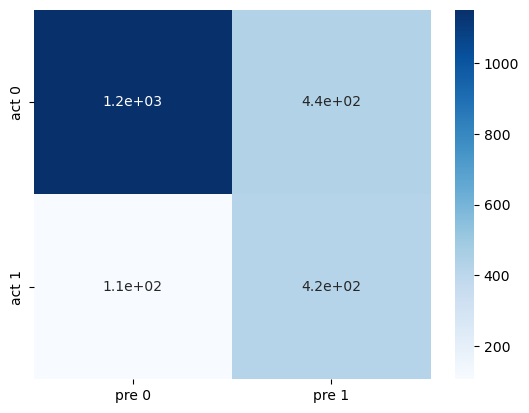

In [33]:
sns.heatmap(cm,annot=True,cmap='Blues',xticklabels=['pre 0','pre 1'],yticklabels=['act 0','act 1'])

11.准备逻辑回归，得出结论
因为是对随机森林的对比归因，所以这里选择l1作为正则化关键字参数来降低多重共线性影响，日常处理需要在数据预处理中先处理

In [34]:
model=lr(penalty='l1',solver='liblinear',max_iter=1000,class_weight='balanced',random_state=2)
model=model.fit(Xtrain_final,Ytrain)
model_pred=model.predict(Xtest_final)
model_pred_proba=model.predict_proba(Xtest_final)[:,1]
auc1=roc_auc_score(Ytest,model_pred_proba)
auc1

0.8370453350540101

In [35]:
coef=model.coef_
df_coef=pd.DataFrame({'feature':Xtrain_final.columns,'coefficient':coef[0]}).sort_values(by='coefficient',ascending=False).reset_index(drop=True)
df_coef

,feature,coefficient
0,InternetService_Fiber optic,0.776962
1,PaymentMethod_Electronic check,0.467117
2,SeniorCitizen_1,0.198916
3,DeviceProtection_No internet service,0.000000
4,OnlineBackup_No internet service,0.000000
5,TechSupport_No internet service,0.000000
6,InternetService_No,0.000000
7,StreamingMovies_No internet service,0.000000
8,StreamingTV_No internet service,-0.002057
9,TechSupport_Yes,-0.322422


12.将两张DataFrame拼在一起得出最终业务结论

In [36]:
data_final=pd.merge(df_importances,df_coef,on='feature',how='outer').sort_values(by='importances',ascending=False).reset_index(drop=True)
data_final

,feature,importances,coefficient
0,Contract_Two year,0.208591,-1.945979
1,InternetService_Fiber optic,0.131378,0.776962
2,Contract_One year,0.122573,-1.106034
3,tenure_3.0,0.117780,-0.705474
4,PaymentMethod_Electronic check,0.114104,0.467117
5,OnlineSecurity_Yes,0.077631,-0.533385
6,TechSupport_Yes,0.070497,-0.322422
7,SeniorCitizen_1,0.031136,0.198916
8,OnlineSecurity_No internet service,0.023683,-1.028742
9,TechSupport_No internet service,0.021856,0.000000


13.得出最终业务结论
1. 合同类型是流失的“生死线”（看 Contract_Two year 和 One year）

· 数据：重要性排第 1 和第 3。系数分别是 -1.94 和 -1.10。
· 结论：签长约（一年或两年）是极其强大的“抗流失护盾”。反过来说，按月付费（Month-to-month）的用户是流失的重灾区。
· 业务行动：运营部要重点针对按月付费用户推出“年签8折”、“首月免单绑定一年”等活动，用合约锁定他们。

2. 光纤用户和手动支付是“高危人群”（看 Fiber optic 和 Electronic check）

· 数据：重要性排第 2 和第 4。系数分别是 0.77 和 0.46（正数，代表促流失）。
· 结论：办了光纤的用户流失率反而高（可能是因为贵，或对网速期望高）；用电子支票手动付款的用户极容易流失（因为每次都要手动，麻烦）。
· 业务行动：客服主动回访光纤套餐用户，解决体验痛点；推出“绑定信用卡自动扣款减免 5 元”的活动，减少支付摩擦。

3. 附加服务是“留人护城河”（看 OnlineSecurity_Yes 和 TechSupport_Yes）

· 数据：重要性较高，系数分别为 -0.53 和 -0.32（负数，抗流失）。
· 结论：只要用户开通了网络安全和技术支持，沉没成本变高，流失概率大幅下降。
· 业务行动：把这两个服务打包成“新客大礼包”，免费试用三个月，培养用户依赖。